# ML02: Download ERA5 predictors (Task 4)
**Goal:** daily ERA5 fields for May-September 1979-2025 over a box around Pakistan and north India (22-38° N, 64-88° E).
These are the "precursors" the model will look at 1, 2 and 3 days before each rain day.

| Variable | Why it matters |
|---|---|
| IVT (moisture flux, east and north parts) | moisture transport into the catchments |
| Total column water vapour | how much moisture the air holds |
| Mean sea-level pressure | monsoon lows and depressions |
| 500 hPa height | westerly troughs and ridges |
| 700 hPa specific humidity | mid-level moisture |
| 850 hPa winds | low-level monsoon flow toward the Himalayas |

**How:** ERA5 at 03, 09, 15 and 21 UTC (the same 03-03 UTC day as IMD), averaged to one value per day, then coarsened to 1° (enough for box averages and small on Drive: about 2 MB per year). The large raw files stay in Colab's temporary disk and are deleted.

**Time:** about 94 CDS requests. Usually 2-6 hours in total, depending on the CDS queue. **It is crash-safe:** if Colab stops, run all cells again and finished years are skipped. You can close the laptop lid only if you use Colab Pro background execution; otherwise keep the tab open.

In [1]:
!pip install -q cdsapi netCDF4

In [2]:
import os, glob, warnings
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=FutureWarning)

BASE = os.environ.get('PML_BASE', '/content/drive/MyDrive/PrecursorML')   # this project
EPE  = os.environ.get('PML_EPE',  '/content/drive/MyDrive/EPE2025')       # flood paper: shapefiles + shared IMD files
DATA, RES = f'{BASE}/data', f'{BASE}/results'
for d in (DATA, RES): os.makedirs(d, exist_ok=True)

TARGET      = 'ChenabRavi'                   # basin whose extreme rain days we predict
PCT         = 95                             # extreme day = IMD basin rain >= 95th percentile of JJAS days
YEARS       = list(range(1979, 2026))
TRAIN_YEARS = list(range(1979, 2025))        # 2025 is kept aside as an independent test
EPISODES    = {'E1': ('2025-08-23', '2025-08-26'), 'E2': ('2025-08-29', '2025-09-03')}   # START-date labels

import zipfile, shutil, gc, time
RAW = '/content/era5_raw'                    # temporary (Colab disk, not Drive)
DAY = f'{DATA}/era5_daily'                   # final daily 1-degree files (Drive)
os.makedirs(RAW, exist_ok=True); os.makedirs(DAY, exist_ok=True)
AREA   = [38, 64, 22, 88]                    # N, W, S, E
TIMES  = ['03:00', '09:00', '15:00', '21:00']
MONTHS = ['05', '06', '07', '08', '09']      # May is needed for the 1-3 day leads of early June
DAYS   = [f'{d:02d}' for d in range(1, 32)]
CDS_API_KEY = 'YOUR_CDS_API_KEY'
with open(os.path.expanduser('~/.cdsapirc'), 'w') as fh:
    fh.write(f'url: https://cds.climate.copernicus.eu/api\nkey: {CDS_API_KEY}\n')
print('ok')

## 1. Helper functions

In [3]:
import cdsapi
c = cdsapi.Client(quiet=True)

def fetch(dataset, request, target):
    """Download one CDS request to `target` (NetCDF). Handles the zip that CDS sometimes returns."""
    tmp = target + '.part'
    c.retrieve(dataset, request, tmp)
    if zipfile.is_zipfile(tmp):
        with zipfile.ZipFile(tmp) as z:
            names = [n for n in z.namelist() if n.endswith('.nc')]
            z.extractall(RAW + '/unzip')
        parts = [xr.open_dataset(f'{RAW}/unzip/{n}').load() for n in names]
        xr.merge(parts, compat='override').to_netcdf(target)
        shutil.rmtree(RAW + '/unzip'); os.remove(tmp)
    else:
        os.replace(tmp, target)

def tidy(ds):
    """Common names: time, latitude, longitude, (level); drop extra coordinates."""
    ren = {}
    if 'valid_time' in ds.dims: ren['valid_time'] = 'time'
    if 'pressure_level' in ds.dims: ren['pressure_level'] = 'level'
    if 'isobaricInhPa' in ds.dims: ren['isobaricInhPa'] = 'level'
    ds = ds.rename(ren)
    return ds.drop_vars([v for v in ('number', 'expver', 'step', 'surface') if v in ds.coords and v not in ds.dims])

def find_var(ds, names, words):
    for n in names:
        if n in ds: return ds[n]
    for v in ds.data_vars:                                   # fallback: search the long name
        ln = ds[v].attrs.get('long_name', '').lower()
        if all(w in ln for w in words): return ds[v]
    raise KeyError(f'{names} not found in {list(ds.data_vars)}')

def to_daily_1deg(ds):
    """4 samples per 03-03 UTC day -> daily mean labelled by start date; 0.25 -> 1 degree."""
    day = (ds['time'] - np.timedelta64(3, 'h')).dt.floor('D')
    n = ds['time'].groupby(day.rename('date')).count()
    out = ds.groupby(day.rename('date')).mean('time')
    out = out.sel(date=n['date'][n.values == 4])               # complete days only
    out = out.sortby('latitude').coarsen(latitude=4, longitude=4, boundary='trim').mean()
    return out.astype('float32')

## 2. Download and process, year by year (2025 first, so you can check it quickly)

In [4]:
SL_VARS = ['vertical_integral_of_eastward_water_vapour_flux', 'vertical_integral_of_northward_water_vapour_flux',
           'mean_sea_level_pressure', 'total_column_water_vapour']
PL_VARS = ['geopotential', 'specific_humidity', 'u_component_of_wind', 'v_component_of_wind']
base = {'product_type': ['reanalysis'], 'month': MONTHS, 'day': DAYS, 'time': TIMES,
        'area': AREA, 'data_format': 'netcdf', 'download_format': 'unarchived'}

for yr in [2025] + YEARS[:-1]:
    out = f'{DAY}/era5_daily_{yr}.nc'
    if os.path.exists(out): continue
    t0 = time.time()
    try:
        f_sl, f_pl = f'{RAW}/sl_{yr}.nc', f'{RAW}/pl_{yr}.nc'
        if not os.path.exists(f_sl):
            fetch('reanalysis-era5-single-levels', {**base, 'year': [str(yr)], 'variable': SL_VARS}, f_sl)
        if not os.path.exists(f_pl):
            fetch('reanalysis-era5-pressure-levels', {**base, 'year': [str(yr)], 'variable': PL_VARS,
                                                     'pressure_level': ['500', '700', '850']}, f_pl)
        sl, pl = tidy(xr.open_dataset(f_sl)), tidy(xr.open_dataset(f_pl))
        e = find_var(sl, ['viwve', 'p71.162'], ['eastward', 'water vapour'])
        n = find_var(sl, ['viwvn', 'p72.162'], ['northward', 'water vapour'])
        z = find_var(pl, ['z'], ['geopotential']); q = find_var(pl, ['q'], ['specific humidity'])
        uu = find_var(pl, ['u'], ['u component']); vv = find_var(pl, ['v'], ['v component'])
        six = xr.Dataset({
            'ivt':   np.hypot(e, n),                                   # kg m-1 s-1
            'viwve': e, 'viwvn': n,
            'msl':   find_var(sl, ['msl'], ['sea level pressure']) / 100.0,      # hPa
            'tcwv':  find_var(sl, ['tcwv'], ['total column', 'water vapour']),   # kg m-2
            'z500':  z.sel(level=500, drop=True) / 9.80665,                       # gpm
            'q700':  q.sel(level=700, drop=True) * 1000.0,                        # g/kg
            'u850':  uu.sel(level=850, drop=True), 'v850': vv.sel(level=850, drop=True)})
        daily = to_daily_1deg(six)
        daily.to_netcdf(out + '.tmp'); os.replace(out + '.tmp', out)
        sl.close(); pl.close(); os.remove(f_sl); os.remove(f_pl); gc.collect()
        print(f'{yr}: {daily.sizes["date"]} days, {os.path.getsize(out)/1e6:.1f} MB, {(time.time()-t0)/60:.1f} min', flush=True)
    except Exception as ex:
        print(f'{yr}: FAILED {repr(ex)[:200]} -> run this cell again later', flush=True)

done = sorted(glob.glob(f'{DAY}/era5_daily_*.nc'))
print(len(done), 'of', len(YEARS), 'years on Drive')

bdbd245e58710b70a272b02ff89aab1e.nc:   0%|          | 0.00/28.7M [00:00<?, ?B/s]

11a792253007e089d646644fdaabf20d.nc:   0%|          | 0.00/90.7M [00:00<?, ?B/s]

1992: 153 days, 2.2 MB, 8.8 min


595c1193df231d5b7254f8de9c8b6e69.nc:   0%|          | 0.00/28.9M [00:00<?, ?B/s]

6183dec274d6d3d3beb26b9b00c1ad20.nc:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

...

cbd8d875fb5ce360d2b91f344b047bb2.nc:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

2018: 153 days, 2.2 MB, 17.2 min


d6f166bdf34d7f8d28a0809597f2eb31.nc:   0%|          | 0.00/28.7M [00:00<?, ?B/s]

c686d06ac776f8f1c1fba0f16f36b5e6.nc:   0%|          | 0.00/90.7M [00:00<?, ?B/s]

2019: 153 days, 2.2 MB, 8.7 min
47 of 47 years on Drive


## 3. Sanity check: IVT on the E1 peak day, and 2025 catchment IVT

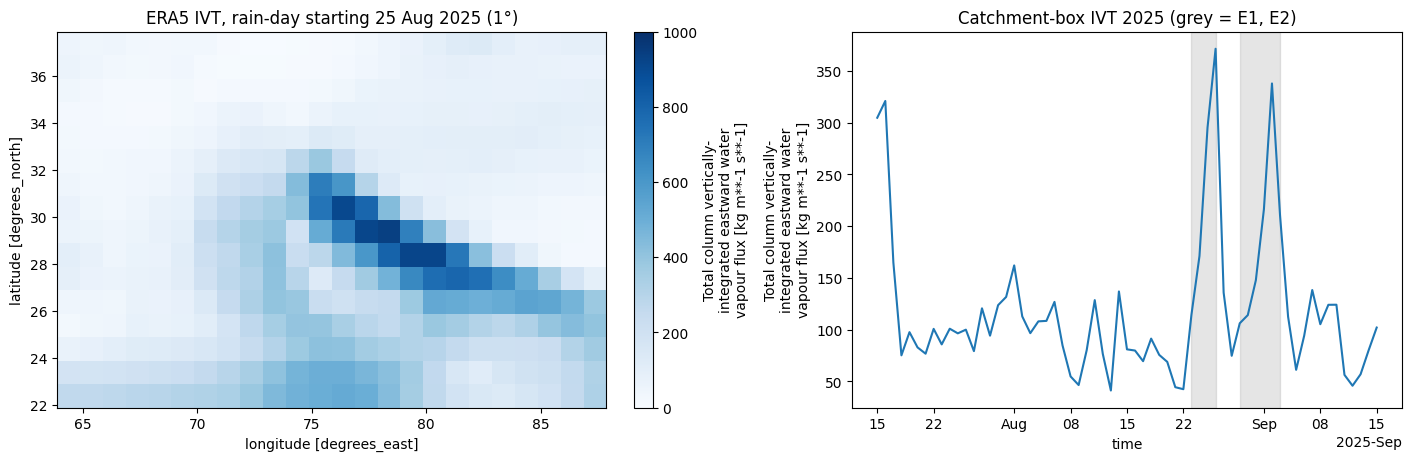

<xarray.Dataset> Size: 2MB
Dimensions:    (date: 153, latitude: 16, longitude: 24)
Coordinates:
  * date       (date) datetime64[ns] 1kB 2025-05-01 2025-05-02 ... 2025-09-30
  * latitude   (latitude) float64 128B 22.38 23.38 24.38 ... 35.38 36.38 37.38
  * longitude  (longitude) float64 192B 64.38 65.38 66.38 ... 85.38 86.38 87.38
Data variables:
    ivt        (date, latitude, longitude) float32 235kB ...
    viwve      (date, latitude, longitude) float32 235kB ...
    viwvn      (date, latitude, longitude) float32 235kB ...
    msl        (date, latitude, longitude) float32 235kB ...
    tcwv       (date, latitude, longitude) float32 235kB ...
    z500       (date, latitude, longitude) float32 235kB ...
    q700       (date, latitude, longitude) float32 235kB ...
    u850       (date, latitude, longitude) float32 235kB ...
    v850       (date, latitude, longitude) float32 235kB ...


In [5]:
d25 = xr.open_dataset(f'{DAY}/era5_daily_2025.nc')
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
d25['ivt'].sel(date='2025-08-25').plot(ax=ax[0], cmap='Blues', vmin=0, vmax=1000)
ax[0].set_title('ERA5 IVT, rain-day starting 25 Aug 2025 (1°)')
box = d25['ivt'].sel(latitude=slice(31, 34), longitude=slice(73.5, 77.5)).mean(['latitude', 'longitude'])
box.sel(date=slice('2025-07-15', '2025-09-15')).plot(ax=ax[1])
for a, b in EPISODES.values(): ax[1].axvspan(pd.Timestamp(a), pd.Timestamp(b), color='grey', alpha=.2)
ax[1].set_title('Catchment-box IVT 2025 (grey = E1, E2)'); plt.show()
print(d25)

## Think about it
1. Why do we use 03, 09, 15 and 21 UTC and not 00, 06, 12, 18?
2. The model will only see fields from the days **before** the rain day. Why is that important? (Hint: "leakage".)